# KMA/MSM – Přednáška 7: Porovnávání středních hodnot pro více skupin

**Blanka Šedivá, KMA FAV ZČU Plzeň**

Notebook doprovází přednášku P07.

## Obsah

1. Proč ne opakované t-testy – simulace mnohonásobného testování
2. One-way ANOVA – výpočet ručně a pomocí knihoven, Welchova ANOVA
3. Testy shody rozptylů (Bartlett, Levene, Brown-Forsythe, Fligner-Killeen)
4. Post-hoc testy (Tukey HSD, Bonferroni, Holm, Games-Howell, Dunnett)
5. Kruskal-Wallisův test a Dunnův post-hoc test
6. Two-way ANOVA s interakcí
7. ANOVA s opakovanými měřeními
8. ANCOVA
9. MANOVA – matice $\mathbf H$, $\mathbf E$ a čtyři testovací statistiky, Boxův M-test, MANCOVA

**Značení:** $g$ je počet skupin, $n$ celkový počet pozorování, $k$ dimenze (počet závislých proměnných).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations
from scipy import stats
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.anova import AnovaRM
from statsmodels.multivariate.manova import MANOVA
from sklearn.datasets import load_iris

RNG = np.random.default_rng(2026)
plt.rcParams.update({'figure.figsize': (11, 4), 'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3,
                     'axes.spines.top': False, 'axes.spines.right': False})
iris = load_iris(as_frame=True)
df_iris = iris.frame.rename(columns={'sepal length (cm)': 'SL', 'sepal width (cm)': 'SW',
                                     'petal length (cm)': 'PL', 'petal width (cm)': 'PW'})
df_iris['druh'] = df_iris['target'].map(dict(enumerate(iris.target_names)))

---
# 1. Proč ne opakované t-testy?

Pro $g$ skupin se **stejnou** střední hodnotou provedeme všech $m=\binom g2$ párových t-testů na hladině 5 % a
sledujeme, jak často alespoň jeden z nich (chybně) zamítne.

In [2]:
B = 3000
rows = []
for g in [2, 3, 5, 8]:
    alespon_jeden = 0
    for _ in range(B):
        grp = [RNG.normal(0, 1, 10) for _ in range(g)]
        p = [stats.ttest_ind(grp[i], grp[j]).pvalue for i, j in combinations(range(g), 2)]
        alespon_jeden += min(p) < 0.05
    m = g * (g - 1) // 2
    rows.append({'g': g, 'počet testů m': m, 'simulace': alespon_jeden / B,
                 '1-(1-alpha)^m (nezávislé testy)': 1 - 0.95**m})
display(pd.DataFrame(rows).set_index('g').round(3))

,počet testů m,simulace,1-(1-alpha)^m (nezávislé testy)
g,,,
2,1,0.054,0.050
3,3,0.131,0.143
5,10,0.288,0.401
8,28,0.508,0.762


Párové testy nejsou nezávislé (sdílejí skupiny), proto je skutečná chyba o něco menší než $1-(1-\alpha)^m$,
ale i tak roste velmi rychle.

---
# 2. One-way ANOVA

Data z původního notebooku *Testy o poloze* a simulovaná data se třemi skupinami.

In [3]:
group_a, group_b, group_c = [12, 14, 13], [15, 16, 14], [10, 11, 12]
print('původní příklad:', stats.f_oneway(group_a, group_b, group_c))

groups = [RNG.normal(m, 1.0, 10) for m in (5.0, 5.5, 6.0)]
g = len(groups)
n = sum(len(x) for x in groups)
means = np.array([x.mean() for x in groups])
xbar = np.concatenate(groups).mean()

SSB = sum(len(x) * (m - xbar)**2 for x, m in zip(groups, means))
SSW = sum(((x - m)**2).sum() for x, m in zip(groups, means))
SST = ((np.concatenate(groups) - xbar)**2).sum()
MSB, MSW = SSB / (g - 1), SSW / (n - g)
F = MSB / MSW
print('\nSSB + SSW = {:.3f}, SST = {:.3f}'.format(SSB + SSW, SST))
print('ručně: F = {:.3f}, p = {:.4f}'.format(F, stats.f.sf(F, g - 1, n - g)))
print('scipy:', stats.f_oneway(*groups))

původní příklad: F_onewayResult(statistic=np.float64(12.0), pvalue=np.float64(0.008000000000000002))

SSB + SSW = 25.980, SST = 25.980
ručně: F = 7.831, p = 0.0021
scipy: F_onewayResult(statistic=np.float64(7.830823547025574), pvalue=np.float64(0.002079232056062745))


Stejný výpočet jako lineární model ve `statsmodels` – výstupem je klasická tabulka ANOVA.

,sum_sq,df,F,PR(>F)
C(skupina),9.537743,2.0,7.830824,0.002079
Residual,16.442654,27.0,NaN,NaN


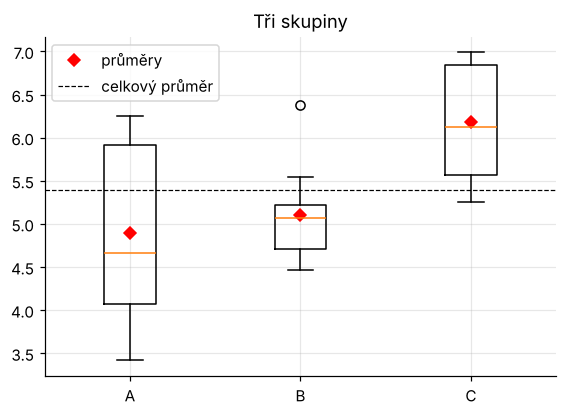

In [4]:
df = pd.DataFrame({'y': np.concatenate(groups), 'skupina': np.repeat(['A', 'B', 'C'], 10)})
model = ols('y ~ C(skupina)', data=df).fit()
display(sm.stats.anova_lm(model, typ=2))

fig, ax = plt.subplots(figsize=(6, 4))
ax.boxplot(groups, tick_labels=['A', 'B', 'C'])
ax.plot(range(1, 4), means, 'rD', label='průměry')
ax.axhline(xbar, color='k', ls='--', lw=0.8, label='celkový průměr')
ax.legend(); ax.set_title('Tři skupiny')
plt.show()

### Reálná data: šířka kališního lístku podle druhu (Iris)

In [5]:
sw = [df_iris.loc[df_iris['druh'] == d, 'SW'].to_numpy() for d in iris.target_names]
print(stats.f_oneway(*sw))
display(df_iris.groupby('druh')['SW'].agg(['mean', 'std', 'count']).round(3))

F_onewayResult(statistic=np.float64(49.160040089612075), pvalue=np.float64(4.492017133309084e-17))


,mean,std,count
druh,,,
setosa,3.428,0.379,50
versicolor,2.770,0.314,50
virginica,2.974,0.322,50


---
# 3. Testy shody rozptylů

`scipy.stats.levene` má výchozí `center='median'`, tj. jde o Brown-Forsytheův test.
Při nesplnění homoskedasticity lze použít Welchovu ANOVA.

In [6]:
from statsmodels.stats.oneway import anova_oneway

for name, data in [('simulovaná data', groups), ('Iris SW', sw)]:
    print(name)
    print('  Bartlett:       p = {:.4f}'.format(stats.bartlett(*data).pvalue))
    print('  Levene:         p = {:.4f}'.format(stats.levene(*data, center='mean').pvalue))
    print('  Brown-Forsythe: p = {:.4f}'.format(stats.levene(*data, center='median').pvalue))
    print('  Fligner-Killeen:p = {:.4f}'.format(stats.fligner(*data).pvalue))
    print('  Welchova ANOVA: p = {:.4g}'.format(anova_oneway(data, use_var='unequal').pvalue))

simulovaná data
  Bartlett:       p = 0.1800
  Levene:         p = 0.0310
  Brown-Forsythe: p = 0.0839
  Fligner-Killeen:p = 0.0687
  Welchova ANOVA: p = 0.00224
Iris SW
  Bartlett:       p = 0.3515
  Levene:         p = 0.5498
  Brown-Forsythe: p = 0.5555
  Fligner-Killeen:p = 0.6338
  Welchova ANOVA: p = 1.433e-14


Simulace: chování testů rozptylů na datech s **těžkými chvosty** a shodnými rozptyly (platí $H_0$).

In [7]:
B = 3000
cnt = {'Bartlett': 0, 'Levene': 0, 'Brown-Forsythe': 0, 'Fligner-Killeen': 0}
for _ in range(B):
    d = [RNG.standard_t(3, 20) for _ in range(3)]
    cnt['Bartlett'] += stats.bartlett(*d).pvalue < 0.05
    cnt['Levene'] += stats.levene(*d, center='mean').pvalue < 0.05
    cnt['Brown-Forsythe'] += stats.levene(*d, center='median').pvalue < 0.05
    cnt['Fligner-Killeen'] += stats.fligner(*d).pvalue < 0.05
print({k: round(v / B, 3) for k, v in cnt.items()})

{'Bartlett': np.float64(0.411), 'Levene': np.float64(0.068), 'Brown-Forsythe': np.float64(0.04), 'Fligner-Killeen': np.float64(0.04)}


Bartlettův test na nenormálních datech zamítá platnou hypotézu mnohem častěji než 5 %. Leveneův test (střed = průměr)
hladinu mírně překračuje, Brown-Forsytheův a Fligner-Killeenův test ji drží.

---
# 4. Post-hoc testy

## 4.1 Tukey HSD

   Multiple Comparison of Means - Tukey HSD, FWER=0.05   
  group1    group2  meandiff p-adj   lower  upper  reject
---------------------------------------------------------
Skupina 1 Skupina 2   0.2086 0.8224 -0.6567  1.074  False
Skupina 1 Skupina 3   1.2867 0.0028  0.4214  2.152   True
Skupina 2 Skupina 3   1.0781 0.0124  0.2127 1.9434   True
---------------------------------------------------------


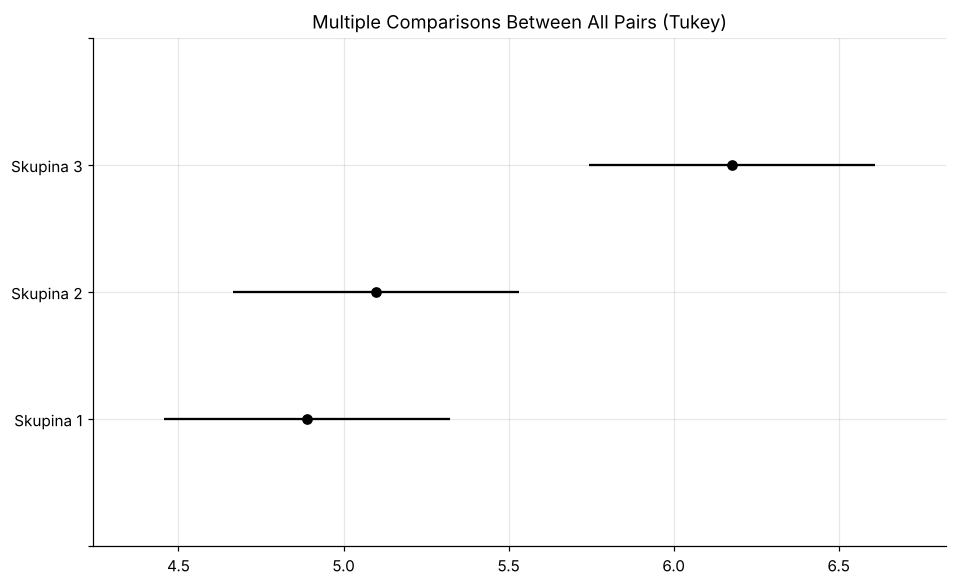

In [8]:
data = np.concatenate(groups)
labels = np.repeat(['Skupina 1', 'Skupina 2', 'Skupina 3'], 10)
tukey = pairwise_tukeyhsd(endog=data, groups=labels, alpha=0.05)
print(tukey)
tukey.plot_simultaneous(); plt.show()

## 4.2 Párové t-testy s korekcí (Bonferroni, Holm)

In [9]:
pairs = list(combinations(range(g), 2))
p_raw = [stats.ttest_ind(groups[i], groups[j]).pvalue for i, j in pairs]
tab = pd.DataFrame({'dvojice': ['{}-{}'.format(i + 1, j + 1) for i, j in pairs], 'p (bez korekce)': p_raw})
for method in ['bonferroni', 'holm']:
    tab['p ' + method] = multipletests(p_raw, method=method)[1]
display(tab.round(4))

,dvojice,p (bez korekce),p bonferroni,p holm
0,1-2,0.5799,1.0000,0.5799
1,1-3,0.0039,0.0117,0.0078
2,2-3,0.0011,0.0033,0.0033


## 4.3 Games-Howell (nestejné rozptyly)

Pro každou dvojici Welchova statistika $t_{ij}$ a Welchovy stupně volnosti; p-hodnota ze studentizovaného
rozpětí pro $g$ skupin: $p=P\left(Q_{g,\nu}>\sqrt2\,|t_{ij}|\right)$.

In [10]:
def games_howell(groups, labels=None):
    g = len(groups)
    labels = labels or [str(i + 1) for i in range(g)]
    rows = []
    for i, j in combinations(range(g), 2):
        a, b = groups[i], groups[j]
        va, vb = a.var(ddof=1) / len(a), b.var(ddof=1) / len(b)
        t = (a.mean() - b.mean()) / np.sqrt(va + vb)
        nu = (va + vb)**2 / (va**2 / (len(a) - 1) + vb**2 / (len(b) - 1))
        p = stats.studentized_range.sf(np.sqrt(2) * abs(t), g, nu)
        rows.append({'dvojice': '{}-{}'.format(labels[i], labels[j]), 'rozdíl': a.mean() - b.mean(),
                     't': t, 'df': nu, 'p': p})
    return pd.DataFrame(rows)

display(games_howell(sw, list(iris.target_names)).round(4))

,dvojice,rozdíl,t,df,p
0,setosa-versicolor,0.658,9.4550,94.6978,0.0000
1,setosa-virginica,0.454,6.4503,95.5472,0.0000
2,versicolor-virginica,-0.204,-3.2058,97.9268,0.0051


## 4.4 Dunnett (srovnání s kontrolní skupinou)

In [11]:
res = stats.dunnett(groups[1], groups[2], control=groups[0])
print(res)

Dunnett's test (95.0% Confidence Interval)
Comparison               Statistic  p-value  Lower CI  Upper CI
 (Sample 0 - Control)      0.598     0.776    -0.606     1.023
 (Sample 1 - Control)      3.687     0.002     0.472     2.101



---
# 5. Kruskal-Wallisův test

$$H=\frac{12}{n(n+1)}\sum_{j=1}^g\frac{R_j^2}{n_j}-3(n+1)\approx\chi^2_{g-1}.$$

In [12]:
r = stats.rankdata(np.concatenate(groups))
idx = np.cumsum([0] + [len(x) for x in groups])
R = [r[idx[j]:idx[j + 1]].sum() for j in range(g)]
H = 12 / (n * (n + 1)) * sum(Rj**2 / len(x) for Rj, x in zip(R, groups)) - 3 * (n + 1)
print('ručně: H = {:.3f}, p = {:.4f}'.format(H, stats.chi2.sf(H, g - 1)))
print('scipy:', stats.kruskal(*groups))

ručně: H = 10.366, p = 0.0056
scipy: KruskalResult(statistic=np.float64(10.36645161290322), pvalue=np.float64(0.005609880805573393))


**Dunnův post-hoc test:** $z_{ij}=\dfrac{\bar R_i-\bar R_j}{\sqrt{\frac{n(n+1)}{12}\left(\frac1{n_i}+\frac1{n_j}\right)}}$
(bez korekce na shody), p-hodnoty korigujeme Holmovou metodou.

In [13]:
def dunn(groups, method='holm'):
    allx = np.concatenate(groups)
    n = len(allx)
    r = stats.rankdata(allx)
    idx = np.cumsum([0] + [len(x) for x in groups])
    Rbar = [r[idx[j]:idx[j + 1]].mean() for j in range(len(groups))]
    rows = []
    for i, j in combinations(range(len(groups)), 2):
        z = (Rbar[i] - Rbar[j]) / np.sqrt(n * (n + 1) / 12 * (1 / len(groups[i]) + 1 / len(groups[j])))
        rows.append({'dvojice': '{}-{}'.format(i + 1, j + 1), 'z': z, 'p': 2 * stats.norm.sf(abs(z))})
    out = pd.DataFrame(rows)
    out['p ' + method] = multipletests(out['p'], method=method)[1]
    return out

display(dunn(groups).round(4))

,dvojice,z,p,p holm
0,1-2,-0.2286,0.8192,0.8192
1,1-3,-2.8956,0.0038,0.0114
2,2-3,-2.6670,0.0077,0.0153


---
# 6. Two-way ANOVA s interakcí

Simulujeme data, kde faktor B má vliv jen na úrovni a3 faktoru A (interakce).

,sum_sq,df,F,PR(>F)
C(faktor_A),10.832165,2.0,4.504616,0.015514
C(faktor_B),25.419873,1.0,21.141989,0.000026
C(faktor_A):C(faktor_B),10.820126,2.0,4.499609,0.015581
Residual,64.926396,54.0,NaN,NaN


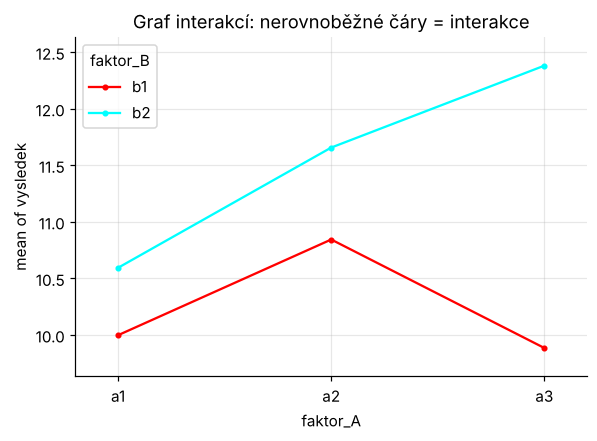

In [14]:
A = np.repeat(['a1', 'a2', 'a3'], 20)
Bf = np.tile(np.repeat(['b1', 'b2'], 10), 3)
y = 10 + (A == 'a2') * 1.0 + ((A == 'a3') & (Bf == 'b2')) * 2.0 + RNG.normal(0, 1, 60)
d2 = pd.DataFrame({'vysledek': y, 'faktor_A': A, 'faktor_B': Bf})

model2 = ols('vysledek ~ C(faktor_A) * C(faktor_B)', data=d2).fit()
display(sm.stats.anova_lm(model2, typ=2))

from statsmodels.graphics.factorplots import interaction_plot
fig, ax = plt.subplots(figsize=(6, 4))
interaction_plot(d2['faktor_A'], d2['faktor_B'], d2['vysledek'], ax=ax)
ax.set_title('Graf interakcí: nerovnoběžné čáry = interakce')
plt.show()

Při významné interakci nelze říct „faktor B má/nemá vliv“ obecně – jeho vliv závisí na úrovni faktoru A.
U nevyvážených dat se výsledky liší podle typu součtů čtverců (`typ=1, 2, 3`).

---
# 7. ANOVA s opakovanými měřeními

Každý subjekt je měřen ve třech časech; subjekty se výrazně liší svou úrovní.

              Anova
    F Value Num DF  Den DF Pr > F
---------------------------------
cas  7.9211 2.0000 22.0000 0.0026

chybně jako one-way ANOVA (ignoruje subjekty): F_onewayResult(statistic=np.float64(0.6183075766533666), pvalue=np.float64(0.5449811244949103))


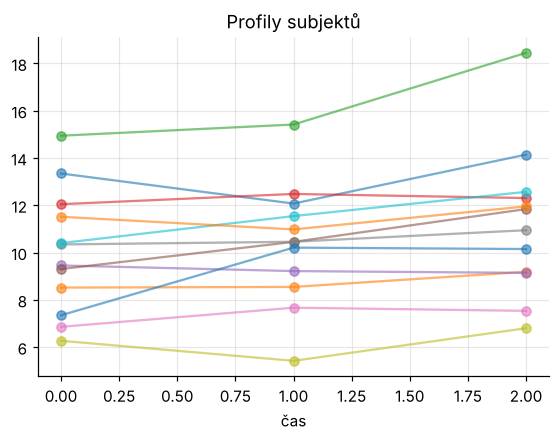

In [15]:
s, c = 12, 3
osoba = RNG.normal(0, 2, s)
rows = [{'subjekt': i, 'cas': t, 'vysledek': 10 + osoba[i] + 0.5 * t + RNG.normal(0, 0.7)}
        for i in range(s) for t in range(c)]
d3 = pd.DataFrame(rows)

print(AnovaRM(d3, depvar='vysledek', subject='subjekt', within=['cas']).fit())
print('chybně jako one-way ANOVA (ignoruje subjekty):',
      stats.f_oneway(*[d3.loc[d3.cas == t, 'vysledek'] for t in range(c)]))

fig, ax = plt.subplots(figsize=(6, 4))
for i in range(s):
    sub = d3[d3.subjekt == i]
    ax.plot(sub['cas'], sub['vysledek'], 'o-', alpha=.6)
ax.set_xlabel('čas'); ax.set_title('Profily subjektů'); plt.show()

ANOVA s opakovanými měřeními odečte variabilitu mezi subjekty a efekt času odhalí; one-way ANOVA, která
subjekty ignoruje, ho v šumu mezi subjekty přehlédne. `AnovaRM` neprovádí korekci na sféricitu – při jejím
porušení je vhodné použít Greenhouse-Geisserovu korekci (např. v balíku `pingouin`) nebo lineární smíšený model.

---
# 8. ANCOVA

Skupina B je v průměru o 2 body lepší, ale navíc v ní jsou lidé s horší počáteční kondicí.

ANOVA bez kovariáty:


,sum_sq,df,F,PR(>F)
C(faktor),52.034552,1.0,2.225876,0.142259
Residual,1122.101134,48.0,NaN,NaN


kontrola shodných směrnic (interakce):


,sum_sq,df,F,PR(>F)
C(faktor),25.456534,1.0,10.090374,2.661852e-03
kovariata,1004.143194,1.0,398.018847,2.780405e-24
C(faktor):kovariata,1.906684,1.0,0.755765,3.891707e-01
Residual,116.051255,46.0,NaN,NaN


ANCOVA:


,sum_sq,df,F,PR(>F)
C(faktor),25.456534,1.0,10.143082,2.571916e-03
kovariata,1004.143194,1.0,400.097951,1.248823e-24
Residual,117.957940,47.0,NaN,NaN


odhad efektu skupiny B: 1.54, 95% interval (0.57, 2.51)


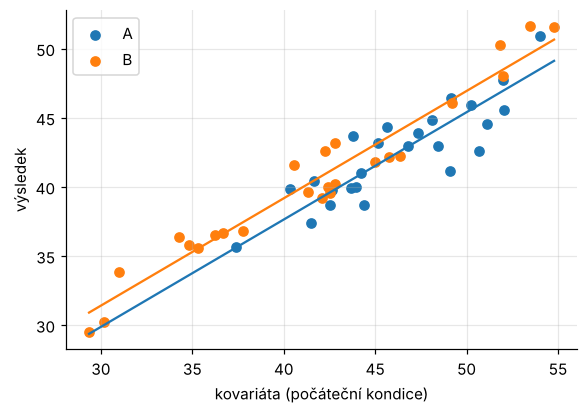

In [16]:
faktor = np.repeat(['A', 'B'], 25)
kovariata = np.r_[RNG.normal(45, 5, 25), RNG.normal(40, 5, 25)]
vysledek = 5 + 0.8 * kovariata + (faktor == 'B') * 2 + RNG.normal(0, 2, 50)
d4 = pd.DataFrame({'vysledek': vysledek, 'faktor': faktor, 'kovariata': kovariata})

print('ANOVA bez kovariáty:')
display(sm.stats.anova_lm(ols('vysledek ~ C(faktor)', data=d4).fit(), typ=2))
print('kontrola shodných směrnic (interakce):')
display(sm.stats.anova_lm(ols('vysledek ~ C(faktor) * kovariata', data=d4).fit(), typ=2))
m_anc = ols('vysledek ~ C(faktor) + kovariata', data=d4).fit()
print('ANCOVA:')
display(sm.stats.anova_lm(m_anc, typ=2))
ci = m_anc.conf_int().loc['C(faktor)[T.B]']
print('odhad efektu skupiny B: {:.2f}, 95% interval ({:.2f}, {:.2f})'.format(m_anc.params['C(faktor)[T.B]'], ci[0], ci[1]))

fig, ax = plt.subplots(figsize=(6, 4))
for lev, col in [('A', 'C0'), ('B', 'C1')]:
    sub = d4[d4.faktor == lev]
    ax.scatter(sub.kovariata, sub.vysledek, c=col, label=lev)
    xs = np.linspace(d4.kovariata.min(), d4.kovariata.max(), 10)
    ax.plot(xs, m_anc.params['Intercept'] + (lev == 'B') * m_anc.params['C(faktor)[T.B]']
            + m_anc.params['kovariata'] * xs, c=col)
ax.set_xlabel('kovariáta (počáteční kondice)'); ax.set_ylabel('výsledek'); ax.legend()
plt.show()

Bez kovariáty se efekt skupiny „schová“ za rozdílnou počáteční kondici; ANCOVA ho po zohlednění kovariáty odhalí.
Skutečná hodnota efektu je 2 a měla by ležet v intervalu spolehlivosti.

---
# 9. MANOVA

Porovnáme tři druhy Iris ve všech čtyřech proměnných ($k=4$, $g=3$, $n=150$).

## 9.1 Matice $\mathbf H$, $\mathbf E$ a testovací statistiky

$$\mathbf H=\sum_j n_j(\bar{\mathbf x}_j-\bar{\mathbf x})(\bar{\mathbf x}_j-\bar{\mathbf x})^T,\qquad
\mathbf E=\sum_j\sum_i(\mathbf x_{ij}-\bar{\mathbf x}_j)(\mathbf x_{ij}-\bar{\mathbf x}_j)^T .$$
Statistiky jsou funkcemi vlastních čísel $\lambda_i$ matice $\mathbf E^{-1}\mathbf H$.

In [17]:
cols = ['SL', 'SW', 'PL', 'PW']
Y = df_iris[cols].to_numpy()
ybar = Y.mean(axis=0)
k = Y.shape[1]
H = np.zeros((k, k)); E = np.zeros((k, k))
for _, d in df_iris.groupby('druh'):
    Yg = d[cols].to_numpy()
    dm = Yg.mean(axis=0) - ybar
    H += len(Yg) * np.outer(dm, dm)
    E += (Yg - Yg.mean(axis=0)).T @ (Yg - Yg.mean(axis=0))

lam = np.sort(np.linalg.eigvals(np.linalg.solve(E, H)).real)[::-1]
print('vlastní čísla E^-1 H:', lam.round(4))
print('Wilks  Lambda = {:.4f}'.format(np.prod(1 / (1 + lam))))
print('Pillai V      = {:.4f}'.format(np.sum(lam / (1 + lam))))
print('Hotelling-Lawley U = {:.4f}'.format(np.sum(lam)))
print('Roy           = {:.4f}'.format(lam[0]))

n, g = len(Y), 3
chi2_bart = -(n - 1 - (k + g) / 2) * np.log(np.prod(1 / (1 + lam)))
print('Bartlettova aproximace: chi2 = {:.1f}, df = {}, p = {:.3g}'.format(
    chi2_bart, k * (g - 1), stats.chi2.sf(chi2_bart, k * (g - 1))))

vlastní čísla E^-1 H: [32.1919  0.2854  0.     -0.    ]
Wilks  Lambda = 0.0234
Pillai V      = 1.1919
Hotelling-Lawley U = 32.4773
Roy           = 32.1919
Bartlettova aproximace: chi2 = 546.1, df = 8, p = 8.87e-113


In [18]:
print(MANOVA.from_formula('SL + SW + PL + PW ~ C(druh)', data=df_iris).mv_test())

                   Multivariate linear model
                                                                
----------------------------------------------------------------
       Intercept         Value  Num DF  Den DF   F Value  Pr > F
----------------------------------------------------------------
          Wilks' lambda  0.0170 4.0000 144.0000 2086.7720 0.0000
         Pillai's trace  0.9830 4.0000 144.0000 2086.7720 0.0000
 Hotelling-Lawley trace 57.9659 4.0000 144.0000 2086.7720 0.0000
    Roy's greatest root 57.9659 4.0000 144.0000 2086.7720 0.0000
----------------------------------------------------------------
                                                                
----------------------------------------------------------------
        C(druh)          Value  Num DF  Den DF   F Value  Pr > F
----------------------------------------------------------------
          Wilks' lambda  0.0234 8.0000 288.0000  199.1453 0.0000
         Pillai's trace  1.1919 8.0000 290.00

Pouze dvě vlastní čísla jsou nenulová ($s=\min(k,g-1)=2$) – rozdíly mezi třemi skupinami leží v nejvýše
dvourozměrném podprostoru (souvislost s lineární diskriminační analýzou).

## 9.2 Předpoklad shodných variančních matic – Boxův M-test

In [19]:
def box_m(*groups):
    g = len(groups)
    k = groups[0].shape[1]
    ns = np.array([len(x) for x in groups])
    n = ns.sum()
    Ss = [np.cov(x, rowvar=False) for x in groups]
    Sp = sum((nj - 1) * Sj for nj, Sj in zip(ns, Ss)) / (n - g)
    M = (n - g) * np.linalg.slogdet(Sp)[1] - sum((nj - 1) * np.linalg.slogdet(Sj)[1] for nj, Sj in zip(ns, Ss))
    c = (2 * k**2 + 3 * k - 1) / (6 * (k + 1) * (g - 1)) * (np.sum(1 / (ns - 1)) - 1 / (n - g))
    stat = (1 - c) * M
    df = (g - 1) * k * (k + 1) / 2
    return stat, df, stats.chi2.sf(stat, df)

print('Boxův M-test (Iris): chi2 = {:.1f}, df = {:.0f}, p = {:.3g}'.format(
    *box_m(*[d[cols].to_numpy() for _, d in df_iris.groupby('druh')])))

Boxův M-test (Iris): chi2 = 140.9, df = 20, p = 3.35e-20


Varianční matice druhů se liší – v takové situaci je nejrobustnější **Pillaiova stopa**. Rozdíl mezi druhy je ale
tak výrazný, že všechny statistiky zamítají $H_0$.

## 9.3 Malý výběr – statistiky se mohou lišit

Příklad ze slajdů: 3 skupiny po 3 pozorováních.

In [20]:
small = pd.DataFrame({'Y1': [5.1, 4.9, 4.7, 6.0, 6.2, 6.1, 7.0, 6.8, 7.1],
                      'Y2': [3.5, 3.0, 3.2, 3.8, 3.9, 4.0, 4.5, 4.3, 4.6],
                      'Group': ['A'] * 3 + ['B'] * 3 + ['C'] * 3})
print(MANOVA.from_formula('Y1 + Y2 ~ Group', data=small).mv_test())

                   Multivariate linear model
                                                               
---------------------------------------------------------------
       Intercept         Value   Num DF Den DF  F Value  Pr > F
---------------------------------------------------------------
          Wilks' lambda   0.0020 2.0000 5.0000 1260.7159 0.0000
         Pillai's trace   0.9980 2.0000 5.0000 1260.7159 0.0000
 Hotelling-Lawley trace 504.2864 2.0000 5.0000 1260.7159 0.0000
    Roy's greatest root 504.2864 2.0000 5.0000 1260.7159 0.0000
---------------------------------------------------------------
                                                               
---------------------------------------------------------------
          Group           Value  Num DF  Den DF F Value  Pr > F
---------------------------------------------------------------
           Wilks' lambda  0.0201 4.0000 10.0000  15.1490 0.0003
          Pillai's trace  1.0226 4.0000 12.0000   3.1387 0.

Wilksova lambda dává $p=0{,}0003$, Pillaiova stopa $p=0{,}055$. U malých výběrů je proto vhodné uvádět,
kterou statistiku používáme, a nespoléhat jen na jednu.

## 9.4 MANOVA vs. samostatné ANOVA

Stejně jako u Hotellingova testu (P06) může MANOVA odhalit rozdíl, který samostatné ANOVA nevidí – pokud se
skupiny liší ve směru „proti“ korelaci proměnných.

In [21]:
Sig = np.array([[1, 0.9], [0.9, 1]])
shifts = [(0, 0), (0.15, -0.15), (-0.15, 0.15)]
rng_c = np.random.default_rng(0)                 # pevny seed pro tento priklad
Yc = np.vstack([rng_c.multivariate_normal(m, Sig, 25) for m in shifts])
dc = pd.DataFrame({'Y1': Yc[:, 0], 'Y2': Yc[:, 1], 'G': np.repeat(['A', 'B', 'C'], 25)})
for col in ['Y1', 'Y2']:
    print('ANOVA {}: p = {:.3f}'.format(col, stats.f_oneway(*[dc.loc[dc.G == lev, col] for lev in 'ABC']).pvalue))
res = MANOVA.from_formula('Y1 + Y2 ~ G', data=dc).mv_test()
print("MANOVA (Pillai): p = {:.2g}".format(res.results['G']['stat'].loc["Pillai's trace", 'Pr > F']))

ANOVA Y1: p = 0.874
ANOVA Y2: p = 0.130
MANOVA (Pillai): p = 2.8e-05


## 9.5 MANCOVA

In [22]:
Group = np.repeat(['A', 'B', 'C'], 20)
Age = RNG.uniform(20, 60, 60)
Y1 = 10 + 0.1 * Age + (Group == 'B') + RNG.normal(0, 1, 60)
Y2 = 5 + 0.05 * Age + 0.5 * (Group == 'C') + RNG.normal(0, 1, 60)
d5 = pd.DataFrame({'Y1': Y1, 'Y2': Y2, 'Group': Group, 'Age': Age})
print(MANOVA.from_formula('Y1 + Y2 ~ C(Group) + Age', data=d5).mv_test())

                  Multivariate linear model
                                                              
--------------------------------------------------------------
       Intercept         Value  Num DF  Den DF F Value  Pr > F
--------------------------------------------------------------
          Wilks' lambda  0.0877 2.0000 55.0000 286.0211 0.0000
         Pillai's trace  0.9123 2.0000 55.0000 286.0211 0.0000
 Hotelling-Lawley trace 10.4008 2.0000 55.0000 286.0211 0.0000
    Roy's greatest root 10.4008 2.0000 55.0000 286.0211 0.0000
--------------------------------------------------------------
                                                              
--------------------------------------------------------------
         C(Group)        Value  Num DF  Den DF  F Value Pr > F
--------------------------------------------------------------
           Wilks' lambda 0.8940 4.0000 110.0000  1.5847 0.1834
          Pillai's trace 0.1077 4.0000 112.0000  1.5931 0.1811
  Hotelling

---
# Shrnutí

| Situace | Normální data, shodné rozptyly | Porušené předpoklady |
|---|---|---|
| $g$ nezávislých skupin | one-way ANOVA + Tukey HSD | Welchova ANOVA + Games-Howell; Kruskal-Wallis + Dunn |
| shoda rozptylů | Bartlettův test | Brown-Forsythe, Fligner-Killeen |
| více faktorů | two-way / three-way ANOVA (pozor na interakce) | – |
| opakovaná měření | ANOVA s opakovanými měřeními | korekce sféricity, smíšené modely, Friedmanův test |
| vliv spojité kovariáty | ANCOVA (shodné směrnice) | – |
| více závislých proměnných | MANOVA (Wilks) | MANOVA (Pillai), permutační testy |

## Úlohy

1. Simulací porovnejte skutečnou hladinu klasické a Welchovy ANOVA pro skupiny rozsahů 5, 10, 40 se směrodatnými odchylkami 3, 1, 1.
2. Na datech Iris proveďte ANOVA pro každou ze čtyř proměnných a výsledky porovnejte s MANOVA. Které post-hoc dvojice se liší?
3. Ověřte, že pro $g=2$ dává MANOVA stejnou p-hodnotu jako dvouvýběrový Hotellingův test z P06.
4. Pro data s opakovanými měřeními použijte Friedmanův test (`scipy.stats.friedmanchisquare`) a porovnejte s `AnovaRM`.